# Part 3 — Presenting results, and model selection
Follows the tutorial's **Presenting your model results** and **EXTRA: P-values and model selection** sections.

R uses `ggeffects`, `sjPlot` and `stargazer` here. Python has no single equivalent, so each is rebuilt from the
fitted model's own numbers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from scipy import stats
import warnings
warnings.filterwarnings("ignore")          # statsmodels convergence chatter; check m.converged instead
pd.set_option("display.width", 140)

# dragons.csv sits next to this notebook (converted from the tutorial's dragons.RData).
# To read the original RData instead:  import pyreadr; dragons = pyreadr.read_r("dragons.RData")["dragons"]
dragons = pd.read_csv("dragons.csv")
dragons["bodyLength2"] = (dragons["bodyLength"] - dragons["bodyLength"].mean()) / dragons["bodyLength"].std()

In [2]:
dragons["sample"] = dragons["mountainRange"].astype(str) + ":" + dragons["site"].astype(str)
mixed_lmer2 = smf.mixedlm("testScore ~ bodyLength2", dragons, groups=dragons["mountainRange"],
                          re_formula="1",                       # random intercept for range
                          vc_formula={"sample": "0 + C(sample)"}).fit(reml=True)
mixed_ranslope = smf.mixedlm("testScore ~ bodyLength2", dragons, groups=dragons["mountainRange"],
                             re_formula="~bodyLength2",
                             vc_formula={"sample": "0 + C(sample)",
                                         "sample_slope": "0 + C(sample):bodyLength2"}).fit(reml=True, method=["powell", "lbfgs"])

## Plotting model predictions

**Tutorial R block 25** — population-level prediction with an error band
```r
pred.mm <- ggpredict(mixed.lmer2, terms = c("bodyLength2"))
(ggplot(pred.mm) + geom_line(aes(x = x, y = predicted)) +
   geom_ribbon(aes(x = x, ymin = predicted - std.error, ymax = predicted + std.error), ...) +
   geom_point(data = dragons, aes(x = bodyLength2, y = testScore, colour = mountainRange)) + ...)
```
Python equivalent:

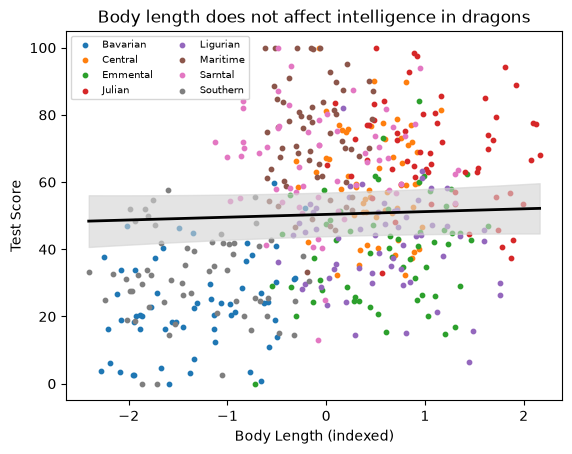

In [3]:
# population-level (fixed-effects) prediction: X @ beta, SE from the fixed-effect covariance
fe = mixed_lmer2.fe_params
V = mixed_lmer2.cov_params().loc[fe.index, fe.index].values
x = np.linspace(dragons.bodyLength2.min(), dragons.bodyLength2.max(), 100)
X = np.column_stack([np.ones_like(x), x])
pred = X @ fe.values
se = np.sqrt(np.einsum("ij,jk,ik->i", X, V, X))

for name, g in dragons.groupby("mountainRange"):
    plt.scatter(g.bodyLength2, g.testScore, s=10, label=name)
plt.plot(x, pred, color="k", lw=2)
plt.fill_between(x, pred - se, pred + se, color="lightgrey", alpha=0.6)
plt.xlabel("Body Length (indexed)"); plt.ylabel("Test Score")
plt.title("Body length does not affect intelligence in dragons")
plt.legend(fontsize=7, ncol=2); plt.show()

**Tutorial R block 26** — one line per mountain range
```r
ggpredict(mixed.lmer2, terms = c("bodyLength2", "mountainRange"), type = "re") %>% plot()
```
Python equivalent:

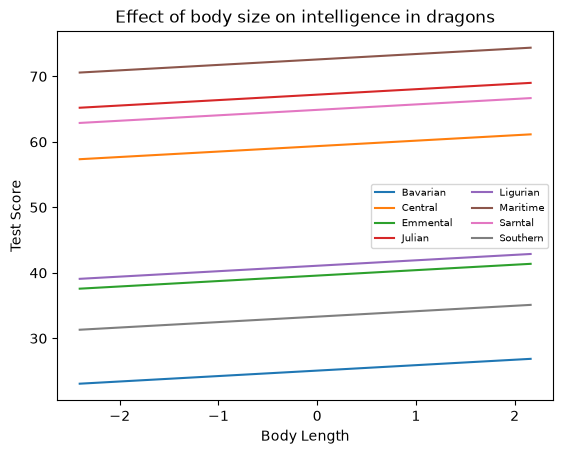

In [4]:
re = mixed_lmer2.random_effects
for r in sorted(re):
    shift = re[r]["Group"]                         # this range's intercept deviation
    plt.plot(x, fe["Intercept"] + shift + fe["bodyLength2"] * x, label=r)
plt.xlabel("Body Length"); plt.ylabel("Test Score")
plt.title("Effect of body size on intelligence in dragons")
plt.legend(fontsize=7, ncol=2); plt.show()

**Tutorial R block 27** — random-effect deviations by mountain range
```r
library(sjPlot)
(re.effects <- plot_model(mixed.ranslope, type = "re", show.values = TRUE))
```
Python equivalent:

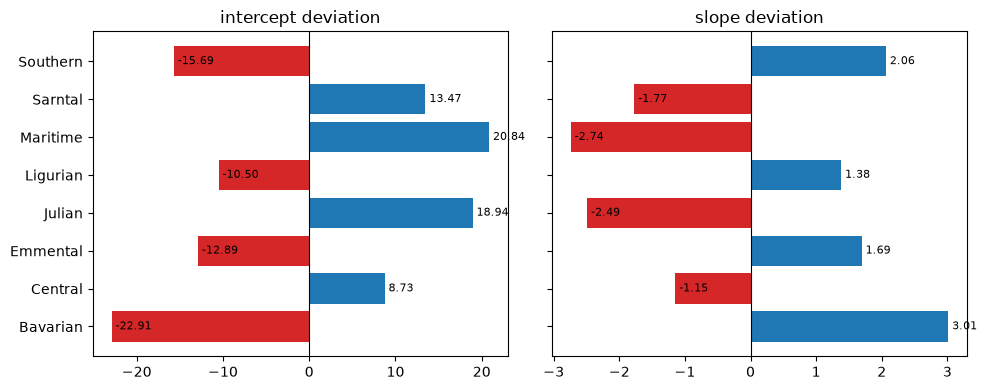

              Mixed Linear Model Regression Results
Model:                MixedLM    Dependent Variable:    testScore 
No. Observations:     480        Method:                REML      
No. Groups:           8          Scale:                 208.7364  
Min. group size:      60         Log-Likelihood:        -1984.3442
Max. group size:      60         Converged:             Yes       
Mean group size:      60.0                                        
------------------------------------------------------------------
                         Coef.  Std.Err.   z   P>|z| [0.025 0.975]
------------------------------------------------------------------
Intercept                51.371    6.522 7.876 0.000 38.587 64.154
bodyLength2               0.561    1.866 0.301 0.764 -3.097  4.219
Group Var               306.373   11.882                          
Group x bodyLength2 Cov -40.285    3.534                          
bodyLength2 Var           5.297    6.145                          
sample Var

In [5]:
re_df = pd.DataFrame({r: v[["Group", "bodyLength2"]] for r, v in mixed_ranslope.random_effects.items()}).T
re_df.columns = ["intercept deviation", "slope deviation"]
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, col in zip(axs, re_df.columns):
    ax.barh(re_df.index, re_df[col], color=np.where(re_df[col] > 0, "tab:blue", "tab:red"))
    ax.axvline(0, color="k", lw=0.8); ax.set_title(col)
    for i, v in enumerate(re_df[col]): ax.text(v, i, f" {v:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()
print(mixed_ranslope.summary())

## Tables

**Tutorial R block 29**
```r
stargazer(mixed.lmer2, type = "text", digits = 3, star.cutoffs = c(0.05, 0.01, 0.001))
```
Python equivalent:

In [6]:
tbl = pd.DataFrame({"estimate": mixed_lmer2.fe_params, "SE": mixed_lmer2.bse_fe,
                    "z": mixed_lmer2.tvalues[mixed_lmer2.fe_params.index],
                    "p": mixed_lmer2.pvalues[mixed_lmer2.fe_params.index]})
tbl["sig"] = pd.cut(tbl["p"], [-1, 0.001, 0.01, 0.05, 1], labels=["***", "**", "*", ""])
print(tbl.round(3))
print(f"\nObservations: {mixed_lmer2.nobs}   Log-likelihood (REML): {mixed_lmer2.llf:.3f}")
print("Random effects (variances):")
print(f"  mountainRange: {float(mixed_lmer2.cov_re.iloc[0,0]):.3f}")
print(f"  sample:        {float(mixed_lmer2.vcomp[0]):.3f}")
print(f"  residual:      {mixed_lmer2.scale:.3f}")

             estimate     SE      z      p  sig
Intercept      50.386  6.507  7.743  0.000  ***
bodyLength2     0.831  1.711  0.486  0.627     

Observations: 480   Log-likelihood (REML): -1985.195
Random effects (variances):
  mountainRange: 327.591
  sample:        23.092
  residual:      208.579


## EXTRA: P-values and model selection — fixed effects structure

Comparing models with **different fixed effects** needs maximum likelihood (`REML = FALSE` / `reml=False`), not REML.

**Tutorial R block 30**
```r
full.lmer <- lmer(testScore ~ bodyLength2 + (1|mountainRange) + (1|sample), data = dragons, REML = FALSE)
reduced.lmer <- lmer(testScore ~ 1 + (1|mountainRange) + (1|sample), data = dragons, REML = FALSE)
```
Python equivalent:

In [6]:
full = smf.mixedlm("testScore ~ bodyLength2", dragons, groups=dragons["mountainRange"],
                   re_formula="1", vc_formula={"sample": "0 + C(sample)"}).fit(reml=False)
reduced = smf.mixedlm("testScore ~ 1", dragons, groups=dragons["mountainRange"],
                      re_formula="1", vc_formula={"sample": "0 + C(sample)"}).fit(reml=False)

**Tutorial R block 31** — likelihood-ratio test
```r
anova(reduced.lmer, full.lmer)  # the two models are not significantly different
```
Python equivalent:

In [7]:
LR = 2 * (full.llf - reduced.llf)
df = len(full.fe_params) - len(reduced.fe_params)      # 1 extra fixed effect
p = stats.chi2.sf(LR, df)

k_full, k_red = len(full.params), len(reduced.params)    # fixed effects + variance parameters (+1 below for the residual)
print(pd.DataFrame({"logLik": [reduced.llf, full.llf],
                    "AIC": [-2*reduced.llf + 2*(k_red+1), -2*full.llf + 2*(k_full+1)]},
                   index=["reduced", "full"]).round(2))
print(f"\nChisq = {LR:.3f}, df = {df}, p = {p:.3f}")

          logLik      AIC
reduced -1989.53  3987.05
full    -1989.38  3988.77

Chisq = 0.287, df = 1, p = 0.592


**Reading it:** a large p means adding `bodyLength2` doesn't improve the fit. The tutorial reaches the same conclusion.

**Random effects structure:** to compare models that differ only in random effects (e.g. with vs without random slopes),
keep the fixed effects identical and compare REML fits. Note the tutorial's caution that a variance tested at its boundary (0)
makes the χ² p-value conservative.

In [8]:
# example: does adding random slopes improve the nested model? (same fixed effects, REML fits)
LR_re = 2 * (mixed_ranslope.llf - mixed_lmer2.llf)
extra = (len(mixed_ranslope.params) - len(mixed_lmer2.params))
print(f"LR = {LR_re:.2f}, extra variance parameters = {extra}, naive p = {stats.chi2.sf(LR_re, extra):.3f}")

LR = 1.70, extra variance parameters = 3, naive p = 0.637
